# Industry Bias ABM - Convergence Analysis

This notebook reproduces the results analysis presented in Justin & Trpin, "Industry Sponsorship as Meta-Evidence: A Simulation Study".

This notebook presents the analysis of the simulation results for three scenarios:
- **Base scenario**: Small study size.
- **Different weights**: Comparing variations of only one type of responding to industry bias .
- **Hard scenario**: An alternative scenario where there are too many hypotheses for agents to test.

The code below calculates convergence rates from the ABM simulation results and visualizes the impact of different industry bias styles across these three scenarios.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast
import os

# Plotting style adjustments to match base_scenario_final.png
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.linestyle'] = ':'
plt.rcParams['grid.color'] = '#bbbbbb'
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16


In [16]:
def parse_set(s):
    if pd.isna(s): return set()
    if isinstance(s, set): return s
    s = str(s).strip()
    if s == 'set()': return set()
    if s.startswith('{') and s.endswith('}'):
        s_inner = s[1:-1]
        if not s_inner.strip():
            return set()
        return set(float(x.strip()) for x in s_inner.split(','))
    return set()


# Columns the analyses actually read; everything else is skipped at read time.
NEEDED_COLUMNS = ['round', 'bandits', 'pub_bias', 'site_bias', 'style', 'active_hypotheses']
OPTIONAL_COLUMNS = ['success_testing_comparison']   # only the evaluation analysis needs this


def map_unique(series, fn):
    """Apply `fn` once per distinct value instead of once per row.

    These columns hold very few distinct strings per file: `bandits` is usually constant,
    the bias tuples take one value per parameter level, and `active_hypotheses` at most one
    per hypothesis. Parsing row by row is therefore nearly all waste - and with many
    hypotheses it is also what exhausts memory, because a per-row parse builds a separate
    list or set object for every row instead of sharing a handful.
    """
    return series.map({value: fn(value) for value in series.unique()})


def sole_active_from_string(s):
    """The one hypothesis in a raw `active_hypotheses` cell, or NaN if agents are split."""
    active = parse_set(s)
    return next(iter(active)) if len(active) == 1 else np.nan


def load_and_preprocess(filepath):
    available = pd.read_csv(filepath, nrows=0).columns
    missing = [column for column in NEEDED_COLUMNS if column not in available]
    if missing:
        raise ValueError(f"{os.path.basename(filepath)} is missing required column(s): {missing}")

    usecols = [column for column in NEEDED_COLUMNS + OPTIONAL_COLUMNS if column in available]
    df = pd.read_csv(filepath, usecols=usecols, dtype={'style': 'category'})

    # Best hypothesis and the two industry bias levels, parsed once per distinct value.
    df['best_hypothesis'] = map_unique(df['bandits'], lambda s: max(ast.literal_eval(s)))
    df['pub_bias_ind'] = map_unique(df['pub_bias'], lambda s: ast.literal_eval(s)[1])
    df['site_bias_ind'] = map_unique(df['site_bias'], lambda s: ast.literal_eval(s)[1])

    # NaN marks a round in which public agents are split across several hypotheses.
    df['sole_active'] = map_unique(df['active_hypotheses'], sole_active_from_string)
    # Rows share one set object per distinct string - the analyses only ever read them.
    df['active_hypotheses'] = map_unique(df['active_hypotheses'], parse_set)

    # Vectorised: a split round is NaN and compares False, as does a wrong singleton.
    df['converged_round'] = df['sole_active'] == df['best_hypothesis']

    # Runs are written consecutively and each one starts at round 1.
    df['unique_run_id'] = (df['round'] == 1).cumsum()

    return df

In [17]:
def identify_bias_column(df):
    """Return the column holding the industry bias parameter that varies, plus a label."""
    unique_pub = df['pub_bias_ind'].nunique()
    unique_site = df['site_bias_ind'].nunique()

    if unique_pub > 1 and unique_site <= 1:
        return 'pub_bias_ind', 'Publication bias'

    # For both design bias and industry selection, site_bias_ind varies.
    # We will default to 'Industry Selection / Design Bias' as title.
    return 'site_bias_ind', 'Industry selection / Design bias'


def summarise_runs(runs, bias_col):
    """Turn one boolean outcome per run into per-(style, bias level) rates with 95% CIs.

    `runs` must have the columns: style, <bias_col>, and 'outcome' (bool per run).
    """
    rates = runs.groupby(['style', bias_col])['outcome'].agg(['mean', 'count', 'std']).reset_index()

    # 95% Confidence Interval for a proportion/mean (1.96 * standard error)
    rates['ci'] = 1.96 * rates['std'] / np.sqrt(rates['count'])
    rates['ci'] = rates['ci'].fillna(0) # Handle NaN if count is 1

    rates['rate'] = rates['mean'] * 100 # percentage
    rates['ci'] *= 100 # percentage CI

    return rates


def calculate_convergence_rate(df):
    """Share of runs in which public agents end up testing only the best hypothesis."""
    bias_col, bias_name = identify_bias_column(df)

    # A run is considered converged if in ALL of the last N rounds, public agents exclusively test the best hypothesis
    def run_converged(group):
        # Use last 45 rounds for base/easy, or last 4 for hard scenario (10 rounds total)
        n_rounds = 45 if len(group) >= 50 else 4
        last_n = group.tail(n_rounds)
        return last_n['converged_round'].all()

    runs = df.groupby('unique_run_id').apply(run_converged).reset_index(name='outcome')

    # Merge back the style and bias level for each run
    run_info = df.groupby('unique_run_id').agg({
        'style': 'first',
        bias_col: 'first'
    }).reset_index()

    runs = pd.merge(runs, run_info, on='unique_run_id')

    return summarise_runs(runs, bias_col), bias_col, bias_name

### Trajectory breakdown: what happens during the checking window

`calculate_convergence_rate` collapses the end of a run into one bit: were public agents on the best
hypothesis, and only that one, in every round of the window? That treats every kind of failure alike.
The breakdown below splits the same window into mutually exclusive, exhaustive categories.

Per round, public agents are in one of three states: all on the best hypothesis (*optimal*), all on the
same worse one (*suboptimal*), or spread over several hypotheses (*split*). A **switch** means the whole
group moves together from one hypothesis to another; if only some agents move, the round is *split*, not
a switch. Reading the window as a sequence of those states gives:

| Category | Meaning |
| --- | --- |
| Stable optimal | Agents stay on the best hypothesis for the whole window |
| Stable suboptimal | Agents stay on one and the same worse hypothesis |
| One switch (ended better) | A single switch, onto a hypothesis with a higher success rate |
| One switch (ended worse) | A single switch, onto one with a lower success rate |
| Multiple switches | Two or more switches |
| Never converged | Agents are split in every round of the window |

**Direction of movement.** Every switching category is read the same way: compare the hypothesis the
agents ended the window on with the one they started it on. This is a **net** comparison of the two
endpoints, so a run that dips to a worse hypothesis and then climbs past its starting point still counts
as having ended better. With `detail_multiple_switches=True`, *Multiple switches* is likewise replaced by
*ended better*, *ended worse*, and *ended same* — the last for runs that wandered off and returned to
where they began, which cannot happen with a single switch.

Note that *ended better* says the agents finished above where they began, not that they reached the
optimum; with 55 hypotheses most such runs end well short of it. **Stable optimal** is the category that
tracks the optimum, and it is the one that lines up with the convergence analysis.

Split rounds are handled by the `split_rounds` argument. With `'ignore'` (default) they are read as
transitional and dropped before switches are detected, so `optimal, split, optimal` counts as stable
optimal; the function reports how many runs this affected. With `'separate'`, any run mixing split and
converged rounds goes into a further category, **Not fully converged** — under that setting *Stable
optimal* reproduces `calculate_convergence_rate` exactly for the same window length.

**When split rounds can occur.** Two conditions are needed, and in the current result files neither
scenario meets both, so `split_rounds` makes no difference to either table:

- *More than one public agent.* The hard scenario runs a single public agent, so `active_hypotheses`
  is a singleton by construction and splits are impossible at any round.
- *A stochastic choice.* Public agents anneal their softmax temperature to zero at the half-way point
  of the run, after which they pick by `argmax` over evaluations they all share — identical choices,
  never split. The base scenario has 5 public agents and splits are the norm early (~90% of rows in the
  first rounds), but over a 100-round run its last split round is 49.

So splits would reappear in the base scenario with a window longer than half the run, and in the hard
scenario only if it were rerun with more than one public agent.

In [19]:
BASE_TRAJECTORY_CATEGORIES = [
    'Stable optimal',
    'Stable suboptimal',
    'One switch (ended better)',
    'One switch (ended worse)',
]

# Used in place of a single 'Multiple switches' when detail_multiple_switches=True.
MULTIPLE_SWITCH_CATEGORIES = [
    'Multiple switches (ended better)',
    'Multiple switches (ended worse)',
    'Multiple switches (ended same)',
]


def trajectory_categories(split_rounds='ignore', detail_multiple_switches=False):
    """The ordered, exhaustive list of categories a run can be assigned under these settings."""
    categories = list(BASE_TRAJECTORY_CATEGORIES)
    categories += MULTIPLE_SWITCH_CATEGORIES if detail_multiple_switches else ['Multiple switches']

    if split_rounds == 'separate':
        categories.append('Not fully converged')
    categories.append('Never converged')

    return categories


def sole_active_hypothesis(active):
    """The hypothesis every public agent is testing, or NaN if they are split across several."""
    return next(iter(active)) if len(active) == 1 else np.nan


def classify_trajectory(states, best, split_rounds='ignore', detail_multiple_switches=False):
    """Assign one run's checking window to a trajectory category.

    `states` is the per-round list of sole active hypotheses, with NaN (or None) for rounds
    where public agents are split; `best` is the optimal hypothesis for that run.

    Every switching category is read the same way: compare the hypothesis the agents ended
    the window on with the one they started it on. A single switch is therefore 'ended
    better' or 'ended worse' according to the two success rates, regardless of whether
    either end happens to be the optimum. With `detail_multiple_switches`, runs with two or
    more switches are split by the same net comparison, plus 'ended same' for runs that
    wandered off and came back. Only the endpoints matter, so temporary downgrades along
    the way do not disqualify an overall improvement.
    """
    if all(pd.isna(state) for state in states):
        return 'Never converged'

    if split_rounds == 'separate' and any(pd.isna(state) for state in states):
        return 'Not fully converged'

    # Drop split rounds, then collapse repeats so only genuine switches are left.
    path = []
    for state in states:
        if not pd.isna(state) and (not path or state != path[-1]):
            path.append(state)

    if len(path) == 1:
        return 'Stable optimal' if path[0] == best else 'Stable suboptimal'

    if len(path) == 2:
        # Consecutive entries always differ, so one switch is either up or down.
        return 'One switch (ended better)' if path[1] > path[0] else 'One switch (ended worse)'

    if not detail_multiple_switches:
        return 'Multiple switches'

    # Net movement across the window: compare the endpoints, ignore the route taken.
    if path[-1] > path[0]:
        return 'Multiple switches (ended better)'
    if path[-1] < path[0]:
        return 'Multiple switches (ended worse)'
    return 'Multiple switches (ended same)'


def calculate_trajectory_breakdown(df, n_rounds=2, split_rounds='ignore', detail_multiple_switches=False):
    """Break the last `n_rounds` recorded rounds of every run into trajectory categories.

    A finer-grained version of `calculate_convergence_rate`: instead of one converged/not
    bit per run, each run is placed in exactly one of the categories returned by
    `trajectory_categories`, so within a (style, bias level) cell the rates sum to 100%.

    Switching runs are classified by net movement - whether the hypothesis the agents ended
    the window on is better, worse, or the same as the one they started it on. Note that
    'ended better' does not mean they reached the optimum, only that they finished above
    where they began; 'Stable optimal' remains the category that tracks the optimum.

    `split_rounds` controls rounds where public agents are spread over several hypotheses:
      'ignore'   - treat them as transitional and drop them before detecting switches
      'separate' - route runs that mix split and converged rounds to 'Not fully converged'

    `detail_multiple_switches` splits 'Multiple switches' into the same better/worse/same
    reading already used for single switches.

    Returns (breakdown, bias_col, bias_name). `breakdown` is tidy: one row per
    (style, bias level, trajectory), with 'rate' as a percentage and 'ci' as its 95% interval.
    """
    if split_rounds not in ('ignore', 'separate'):
        raise ValueError(f"split_rounds must be 'ignore' or 'separate', got {split_rounds!r}.")

    bias_col, bias_name = identify_bias_column(df)

    # Only the tail of each run matters, so cut the frame down before doing per-row work.
    # Prefer the precomputed sole_active column: sorting a float column is far cheaper than
    # sorting the set objects in active_hypotheses, which matters at tens of millions of rows.
    state_column = 'sole_active' if 'sole_active' in df.columns else 'active_hypotheses'
    columns = ['unique_run_id', 'round', state_column, 'best_hypothesis', 'style', bias_col]
    window = df[columns].sort_values(['unique_run_id', 'round']).groupby('unique_run_id').tail(n_rounds).copy()

    if state_column == 'active_hypotheses':
        window['sole_active'] = window['active_hypotheses'].apply(sole_active_hypothesis)

    runs = window.groupby('unique_run_id').agg(
        states=('sole_active', list),
        best=('best_hypothesis', 'first'),
        style=('style', 'first'),
        **{bias_col: (bias_col, 'first')}
    ).reset_index()

    runs['trajectory'] = [classify_trajectory(states, best, split_rounds, detail_multiple_switches)
                          for states, best in zip(runs['states'], runs['best'])]

    if split_rounds == 'ignore':
        affected = np.mean([any(pd.isna(state) for state in states) for states in runs['states']]) * 100
        print(f"  -> {affected:.1f}% of runs had at least one split round in the last {n_rounds} "
              f"round(s); those rounds are ignored when detecting switches.")

    # One binomial rate per category, using the same CI convention as the other analyses.
    categories = trajectory_categories(split_rounds, detail_multiple_switches)

    parts = []
    for category in categories:
        runs['outcome'] = runs['trajectory'] == category
        rates = summarise_runs(runs, bias_col)
        rates['trajectory'] = category
        parts.append(rates)

    breakdown = pd.concat(parts, ignore_index=True)
    breakdown['trajectory'] = pd.Categorical(breakdown['trajectory'], categories, ordered=True)

    return breakdown.sort_values(['style', bias_col, 'trajectory']).reset_index(drop=True), bias_col, bias_name


def trajectory_table(breakdown, bias_col, decimals=1):
    """Format a breakdown as a wide table: one row per (style, bias level), one column
    per trajectory, each cell '<rate> +- <95% CI>' in percent."""
    cells = breakdown.assign(cell=[f"{rate:.{decimals}f} +- {ci:.{decimals}f}"
                                   for rate, ci in zip(breakdown['rate'], breakdown['ci'])])
    table = cells.pivot(index=['style', bias_col], columns='trajectory', values='cell')

    # Runs per cell, so the reader can see what the percentages are based on.
    table.insert(0, 'n runs', breakdown.groupby(['style', bias_col], observed=True)['count'].first())

    return table

In [20]:
def plot_convergence(rates, bias_col, bias_name, ax=None, ylabel='Correct Convergence Rate (%)'):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
        
    # Map styles to friendly names as per the chart
    style_mapping = {
        'adaptive_adjustment_significance': 'Relative adjustment',
        'down_weighing_neutral': 'Down-weighting',
        'down_weighing': 'Down-weighting', # fallback if used
        'ignore': 'Ignoring industry',
        'normal': 'No adjustment',
        'Solomon': 'Solomon',
        "down_weighing_01": "Down-weighting = 0.1",
        "down_weighing_09": "Down-weighting = 0.9",
        # "adaptive_adjustment_significance": "Relative adjust. w significance" # Optional if it's in the data
    }
    
    rates['Style Name'] = rates['style'].map(lambda x: style_mapping.get(x, x))
    
    # Define styles to match base_scenario_final.png
    plot_styles = {
        'Relative adjustment': {'marker': 'o', 'color': 'black', 'ls': '-', 'lw': 1.5},
        'Down-weighting': {'marker': 's', 'color': '#333333', 'ls': '--', 'lw': 1.5},
        'Ignoring industry': {'marker': '^', 'color': '#666666', 'ls': '-.', 'lw': 1.5},
        'No adjustment': {'marker': 'D', 'color': '#999999', 'ls': ':', 'lw': 1.5},
        'Solomon': {'marker': 'p', 'color': '#444444', 'ls': '-', 'lw': 1.5},
        'Down-weighting = 0.1': {'marker': 's', 'color': '#111111', 'ls': '--', 'lw': 1.5},
        'Down-weighting = 0.9': {'marker': 's', 'color': '#444444', 'ls': '--', 'lw': 1.5},
        # 'Relative adjust. w significance': {'marker': 's', 'color': '#333333', 'ls': '-', 'lw': 1.5}
    }
    
    # Standardize order if possible
    order = ['Relative adjustment', 'Down-weighting', 'Ignoring industry', 'No adjustment', 'Down-weighting = 0.1', 'Down-weighting = 0.9', 'Solomon']
    existing_styles = [s for s in order if s in rates['Style Name'].values]
    # Add any styles not in standard order
    existing_styles += [s for s in rates['Style Name'].unique() if s not in existing_styles]
    
    for style_name in existing_styles:
        subset = rates[rates['Style Name'] == style_name]
        if subset.empty: continue
            
        opts = plot_styles.get(style_name, {'marker': 'o', 'color': 'black', 'ls': '-', 'lw': 1.5})
        ax.errorbar(subset[bias_col], subset['rate'], yerr=subset['ci'], 
                 marker=opts['marker'], color=opts['color'], 
                 linestyle=opts['ls'], linewidth=opts['lw'],
                 label=style_name, markersize=6, capsize=4)
    
    ax.set_xlabel('Industry Bias', fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    ax.set_title(bias_name, fontsize=20, pad=10)
    ax.set_ylim(-5, 105)
    ax.legend(frameon=False, fontsize=16)
    
    return ax

## Scenarios

In [ ]:
# Define the scenarios and their corresponding result files
scenarios = {
     'base': {
        'Design bias': "data/base_sitebias.csv",
         'Publication bias': "data/base_pubbias.csv",
         'Industry selection': "data/base_indselect.csv"
     },
     'hard': {
         'Design bias': 'data/hard_sitebias.csv',
         'Publication bias': 'data/hard_pubbias.csv',
         'Industry selection': 'data/hard_indselect.csv'
     },
     'weights': {
         'Design bias': 'data/diffweight_sitebias.csv',
         'Publication bias': 'data/diffweight_pubbias.csv',
         'Industry selection': 'data/diffweight_indselect.csv'
    }
}

## Generate Plots for Scenarios
This block iterates through the three scenarios, loads the corresponding result files (if they exist), calculates rates, and saves a chart for each scenario.

Set `ANALYSIS` at the top of the cell to choose what the charts show:
- `'convergence'` — the original analysis: runs in which public agents converge on the best hypothesis.

The charts themselves are identical either way; only the underlying rate and the y-axis label change.

Processing base scenario (convergence analysis)...


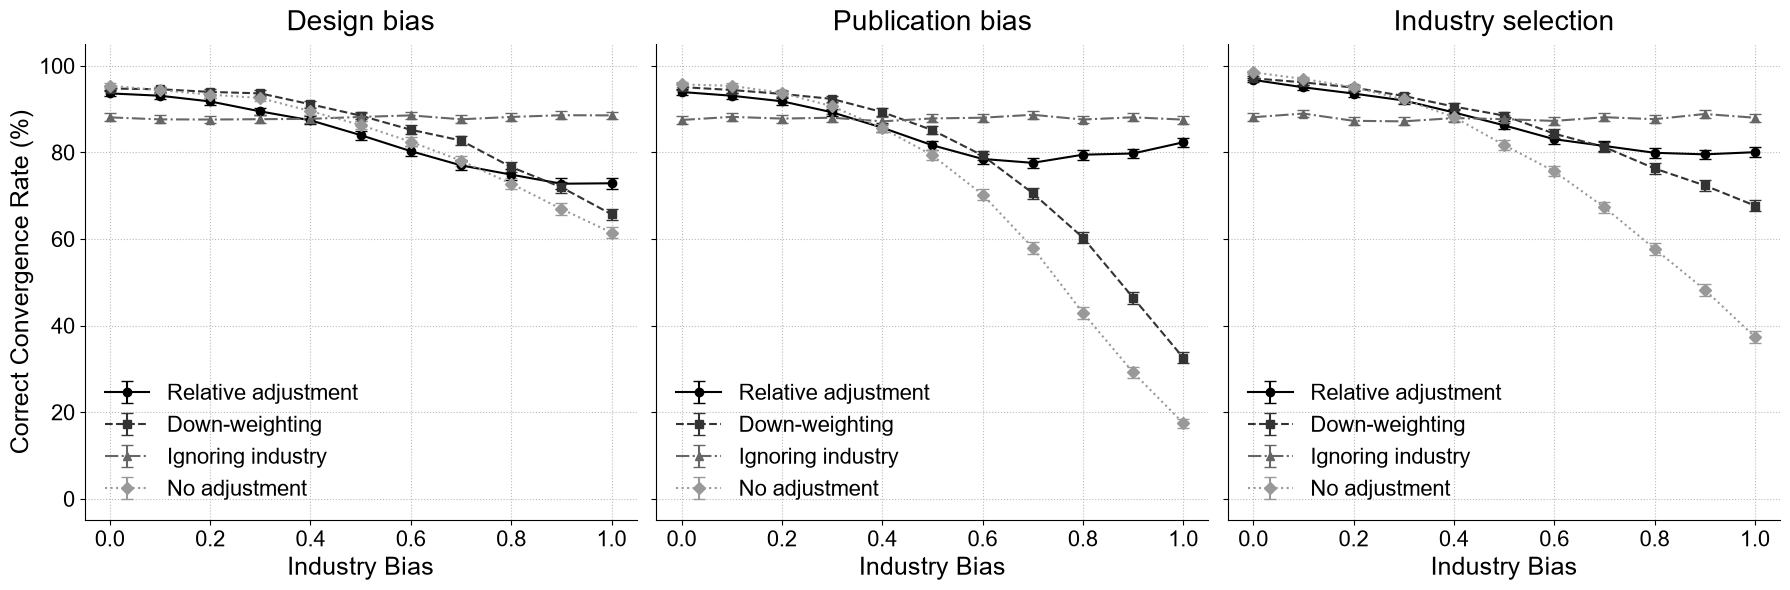

In [ ]:
# Which analysis the charts are built from:
#   'convergence' - runs where public agents end up testing only the best hypothesis

ANALYSIS = 'convergence'

Y_LABELS = {
    'convergence': 'Correct Convergence Rate (%)',
    'evaluation': 'Best Option Ranked First (%)',
}


def run_analysis(df):
    """Dispatch to the selected analysis. Both return (rates, bias_col, bias_name)."""
    if ANALYSIS == 'convergence':
        return calculate_convergence_rate(df)
    raise ValueError(f"Unknown ANALYSIS {ANALYSIS!r}, expected 'convergence' or 'evaluation'.")


def output_filename(scenario_name):
    return f'{scenario_name}_final.png'


for scenario_name, files in scenarios.items():
    print(f"Processing {scenario_name} scenario ({ANALYSIS} analysis)...")
    existing_files = {k: v for k, v in files.items() if os.path.exists(v)}
    
    if existing_files:
        fig, axes = plt.subplots(1, len(existing_files), figsize=(6 * len(existing_files), 6), sharey=True)
        if len(existing_files) == 1:
            axes = [axes]
        
        for i, (title, filepath) in enumerate(existing_files.items()):
            df = load_and_preprocess(filepath)
            rates, bias_col, _ = run_analysis(df)
            plot_convergence(rates, bias_col, title, ax=axes[i], ylabel=Y_LABELS[ANALYSIS])
            if i > 0:
                axes[i].set_ylabel('') # Only show y-label on the first subplot

        plt.tight_layout()
        plt.savefig(output_filename(scenario_name), dpi=800, bbox_inches='tight', format='png')
        plt.show()
    else:
        print(f"  -> No result files found for {scenario_name} scenario. Make sure to add them to the directory.\n")


## Trajectory Breakdown Tables
Same scenario files, same checking window as the convergence analysis, but reported as tables rather
than charts. `BREAKDOWN_ROUNDS` sets how many rounds at the end of each run are inspected.

In [20]:
BREAKDOWN_ROUNDS = 45             # rounds at the end of each run to inspect (matches calculate_convergence_rate)
SPLIT_ROUNDS = 'ignore'           # 'ignore' or 'separate' - see calculate_trajectory_breakdown
DETAIL_MULTIPLE_SWITCHES = True   # split 'Multiple switches' into ended better / worse / same

breakdowns = {}  # (scenario, bias type) -> tidy breakdown, for further work or export

for scenario_name, files in scenarios.items():
    for title, filepath in files.items():
        if not os.path.exists(filepath):
            print(f"\n{scenario_name} / {title} - SKIPPED, no file at {filepath}")
            continue

        print(f"\n{scenario_name} / {title} - last {BREAKDOWN_ROUNDS} round(s), percentages with 95% CI")
        df = load_and_preprocess(filepath)
        breakdown, bias_col, _ = calculate_trajectory_breakdown(
            df, n_rounds=BREAKDOWN_ROUNDS, split_rounds=SPLIT_ROUNDS,
            detail_multiple_switches=DETAIL_MULTIPLE_SWITCHES
        )
        breakdowns[(scenario_name, title)] = (breakdown, bias_col)
        display(trajectory_table(breakdown, bias_col))



base / Design bias - last 45 round(s), percentages with 95% CI
  -> 0.0% of runs had at least one split round in the last 45 round(s); those rounds are ignored when detecting switches.


trajectory                                      n runs Stable optimal  \
style                            site_bias_ind                          
adaptive_adjustment_significance 0.0              5000    93.6 +- 0.7   
                                 0.1              5000    93.1 +- 0.7   
                                 0.2              5000    91.8 +- 0.8   
                                 0.3              5000    89.5 +- 0.9   
                                 0.4              5000    87.4 +- 0.9   
                                 0.5              5000    84.0 +- 1.0   
                                 0.6              5000    80.3 +- 1.1   
                                 0.7              5000    77.0 +- 1.2   
                                 0.8              5000    74.9 +- 1.2   
                                 0.9              5000    72.8 +- 1.2   
                                 1.0              5000    72.9 +- 1.2   
ignore                           0.0              5000    88.1 +- 0.9   
                                 0.1              5000    87.6 +- 0.9   
                                 0.2              5000    87.6 +- 0.9   
                                 0.3              5000    87.7 +- 0.9   
                                 0.4              5000    87.7 +- 0.9   
                                 0.5              5000    88.2 +- 0.9   
                                 0.6              5000    88.5 +- 0.9   
                                 0.7              5000    87.6 +- 0.9   
                                 0.8              5000    88.2 +- 0.9   
                                 0.9              5000    88.6 +- 0.9   
                                 1.0              5000    88.5 +- 0.9   
normal                           0.0              5000    95.4 +- 0.6   
                                 0.1              5000    94.4 +- 0.6   
                                 0.2              5000    93.3 +- 0.7   
                                 0.3              5000    92.5 +- 0.7   
                                 0.4              5000    89.5 +- 0.8   
                                 0.5              5000    86.3 +- 1.0   
                                 0.6              5000    82.4 +- 1.1   
                                 0.7              5000    78.1 +- 1.1   
                                 0.8              5000    72.8 +- 1.2   
                                 0.9              5000    66.9 +- 1.3   
                                 1.0              5000    61.5 +- 1.3   
down_weighing_neutral            0.0              5000    94.7 +- 0.6   
                                 0.1              5000    94.6 +- 0.6   
                                 0.2              5000    94.0 +- 0.7   
                                 0.3              5000    93.6 +- 0.7   
                                 0.4              5000    91.1 +- 0.8   
                                 0.5              5000    88.5 +- 0.9   
                                 0.6              5000    85.2 +- 1.0   
                                 0.7              5000    82.7 +- 1.0   
                                 0.8              5000    76.6 +- 1.2   
                                 0.9              5000    71.9 +- 1.2   
                                 1.0              5000    65.7 +- 1.3   

trajectory                                     Stable suboptimal  \
style                            site_bias_ind                     
adaptive_adjustment_significance 0.0                  1.8 +- 0.4   
                                 0.1                  2.2 +- 0.4   
                                 0.2                  2.5 +- 0.4   
                                 0.3                  3.1 +- 0.5   
                                 0.4                  2.8 +- 0.5   
                                 0.5                  3.7 +- 0.5   
                                 0.6                  4.1 +- 0.5   
                             


base / Publication bias - last 45 round(s), percentages with 95% CI
  -> 0.0% of runs had at least one split round in the last 45 round(s); those rounds are ignored when detecting switches.


trajectory                                     n runs Stable optimal  \
style                            pub_bias_ind                          
adaptive_adjustment_significance 0.0             5000    93.9 +- 0.7   
                                 0.1             5000    93.1 +- 0.7   
                                 0.2             5000    91.8 +- 0.8   
                                 0.3             5000    89.3 +- 0.9   
                                 0.4             5000    85.7 +- 1.0   
                                 0.5             5000    81.6 +- 1.1   
                                 0.6             5000    78.5 +- 1.1   
                                 0.7             5000    77.6 +- 1.2   
                                 0.8             5000    79.5 +- 1.1   
                                 0.9             5000    79.7 +- 1.1   
                                 1.0             5000    82.3 +- 1.1   
ignore                           0.0             5000    87.5 +- 0.9   
                                 0.1             5000    88.2 +- 0.9   
                                 0.2             5000    87.8 +- 0.9   
                                 0.3             5000    88.0 +- 0.9   
                                 0.4             5000    87.2 +- 0.9   
                                 0.5             5000    87.8 +- 0.9   
                                 0.6             5000    88.0 +- 0.9   
                                 0.7             5000    88.7 +- 0.9   
                                 0.8             5000    87.6 +- 0.9   
                                 0.9             5000    88.1 +- 0.9   
                                 1.0             5000    87.6 +- 0.9   
normal                           0.0             5000    95.7 +- 0.6   
                                 0.1             5000    95.4 +- 0.6   
                                 0.2             5000    93.7 +- 0.7   
                                 0.3             5000    90.7 +- 0.8   
                                 0.4             5000    85.6 +- 1.0   
                                 0.5             5000    79.3 +- 1.1   
                                 0.6             5000    70.3 +- 1.3   
                                 0.7             5000    58.0 +- 1.4   
                                 0.8             5000    43.0 +- 1.4   
                                 0.9             5000    29.2 +- 1.3   
                                 1.0             5000    17.5 +- 1.1   
down_weighing_neutral            0.0             5000    95.1 +- 0.6   
                                 0.1             5000    94.4 +- 0.6   
                                 0.2             5000    93.5 +- 0.7   
                                 0.3             5000    92.3 +- 0.7   
                                 0.4             5000    89.3 +- 0.9   
                                 0.5             5000    85.1 +- 1.0   
                                 0.6             5000    79.3 +- 1.1   
                                 0.7             5000    70.6 +- 1.3   
                                 0.8             5000    60.3 +- 1.4   
                                 0.9             5000    46.5 +- 1.4   
                                 1.0             5000    32.6 +- 1.3   

trajectory                                    Stable suboptimal  \
style                            pub_bias_ind                     
adaptive_adjustment_significance 0.0                 2.1 +- 0.4   
                                 0.1                 2.0 +- 0.4   
                                 0.2                 2.3 +- 0.4   
                                 0.3                 2.6 +- 0.4   
                                 0.4                 3.4 +- 0.5   
                                 0.5                 3.6 +- 0.5   
                                 0.6                 4.1 +- 0.5   
                                 0.7                 4.2 +- 0.6   
                 


base / Industry selection - last 45 round(s), percentages with 95% CI
  -> 0.0% of runs had at least one split round in the last 45 round(s); those rounds are ignored when detecting switches.


trajectory                                      n runs Stable optimal  \
style                            site_bias_ind                          
adaptive_adjustment_significance 0.0              5000    96.7 +- 0.5   
                                 0.1              5000    95.0 +- 0.6   
                                 0.2              5000    93.6 +- 0.7   
                                 0.3              5000    92.0 +- 0.8   
                                 0.4              5000    89.2 +- 0.9   
                                 0.5              5000    86.2 +- 1.0   
                                 0.6              5000    83.0 +- 1.0   
                                 0.7              5000    81.5 +- 1.1   
                                 0.8              5000    79.9 +- 1.1   
                                 0.9              5000    79.5 +- 1.1   
                                 1.0              5000    80.0 +- 1.1   
ignore                           0.0              5000    88.1 +- 0.9   
                                 0.1              5000    89.0 +- 0.9   
                                 0.2              5000    87.3 +- 0.9   
                                 0.3              5000    87.2 +- 0.9   
                                 0.4              5000    87.9 +- 0.9   
                                 0.5              5000    87.7 +- 0.9   
                                 0.6              5000    87.3 +- 0.9   
                                 0.7              5000    88.1 +- 0.9   
                                 0.8              5000    87.7 +- 0.9   
                                 0.9              5000    88.9 +- 0.9   
                                 1.0              5000    88.0 +- 0.9   
normal                           0.0              5000    98.5 +- 0.3   
                                 0.1              5000    97.0 +- 0.5   
                                 0.2              5000    95.0 +- 0.6   
                                 0.3              5000    92.2 +- 0.7   
                                 0.4              5000    88.1 +- 0.9   
                                 0.5              5000    81.7 +- 1.1   
                                 0.6              5000    75.6 +- 1.2   
                                 0.7              5000    67.3 +- 1.3   
                                 0.8              5000    57.7 +- 1.4   
                                 0.9              5000    48.3 +- 1.4   
                                 1.0              5000    37.4 +- 1.3   
down_weighing_neutral            0.0              5000    97.1 +- 0.5   
                                 0.1              5000    96.2 +- 0.5   
                                 0.2              5000    95.0 +- 0.6   
                                 0.3              5000    93.0 +- 0.7   
                                 0.4              5000    90.6 +- 0.8   
                                 0.5              5000    88.5 +- 0.9   
                                 0.6              5000    84.3 +- 1.0   
                                 0.7              5000    81.2 +- 1.1   
                                 0.8              5000    76.3 +- 1.2   
                                 0.9              5000    72.4 +- 1.2   
                                 1.0              5000    67.7 +- 1.3   

trajectory                                     Stable suboptimal  \
style                            site_bias_ind                     
adaptive_adjustment_significance 0.0                  1.2 +- 0.3   
                                 0.1                  2.1 +- 0.4   
                                 0.2                  2.3 +- 0.4   
                                 0.3                  2.4 +- 0.4   
                                 0.4                  3.4 +- 0.5   
                                 0.5                  4.5 +- 0.6   
                                 0.6                  4.9 +- 0.6   
                             